In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set clean plot style
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 11

print("Setup complete.")

Setup complete.


In [2]:
from google.colab import files

file_name = "Spotify_2024_Global_Streaming_Data.csv"

# Check if file is already uploaded to Colab memory
if not os.path.exists(file_name):
  print("File not found in current folder. Please select your CSV file:")
  uploaded = files.upload()
else:
  print("Dataset found! Loading automatically...")

# Load data into pandas
df = pd.read_csv(file_name)
print(f"Data loaded: {df.shape} rows, {df.shape} columns.")
df.head(3)

Dataset found! Loading automatically...
Data loaded: (500, 12) rows, (500, 12) columns.


,Country,Artist,Album,Genre,Release Year,Monthly Listeners (Millions),Total Streams (Millions),Total Hours Streamed (Millions),Avg Stream Duration (Min),Platform Type,Streams Last 30 Days (Millions),Skip Rate (%)
0,Germany,Taylor Swift,1989 (Taylor's Version),K-pop,2019,23.10,3695.53,14240.35,4.28,Free,118.51,2.24
1,Brazil,The Weeknd,After Hours,R&B,2022,60.60,2828.16,11120.44,3.90,Premium,44.87,23.98
2,United States,Post Malone,Austin,Reggaeton,2023,42.84,1425.46,4177.49,4.03,Free,19.46,4.77


In [3]:
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicates
print(f"\nDuplicates found: {df.duplicated().sum()}")

# Export cleaned version
df.to_csv("Spotify_2024_Cleaned.csv", index=False)
print("Saved clean file as 'Spotify_2024_Cleaned.csv'.")

Missing values per column:
Country                            0
Artist                             0
Album                              0
Genre                              0
Release Year                       0
Monthly Listeners (Millions)       0
Total Streams (Millions)           0
Total Hours Streamed (Millions)    0
Avg Stream Duration (Min)          0
Platform Type                      0
Streams Last 30 Days (Millions)    0
Skip Rate (%)                      0
dtype: int64

Duplicates found: 0
Saved clean file as 'Spotify_2024_Cleaned.csv'.


In [4]:
# Total streams and hours
total_streams = df["Total Streams (Millions)"].sum()
total_hours = df["Total Hours Streamed (Millions)"].sum()

print(f"Total Streams: {total_streams / 1000:,.2f} Billion")
print(f"Total Hours Streamed: {total_hours / 1000:,.2f} Billion Hours\n")

# Top 5 Artists by total streams
print("--- Top 5 Artists ---")
top_art = df.groupby("Artist")["Total Streams (Millions)"].sum().nlargest(5)
print((top_art / 1000).round(2).astype(str) + " B")

# Average skip rate by genre
print("\n--- Skip Rate by Genre (%) ---")
genre_skip = df.groupby("Genre")["Skip Rate (%)"].mean().sort_values()
print(genre_skip.round(2))

Total Streams: 1,290.58 Billion
Total Hours Streamed: 4,477.18 Billion Hours

--- Top 5 Artists ---
Artist
BTS           124.3 B
Dua Lipa     111.31 B
Bad Bunny    106.22 B
BLACKPINK    102.24 B
Doja Cat       90.1 B
Name: Total Streams (Millions), dtype: object

--- Skip Rate by Genre (%) ---
Genre
Indie        18.29
K-pop        19.11
Classical    19.80
R&B          19.89
Jazz         20.00
Reggaeton    20.10
EDM          20.79
Rock         21.14
Hip Hop      21.70
Pop          23.13
Name: Skip Rate (%), dtype: float64


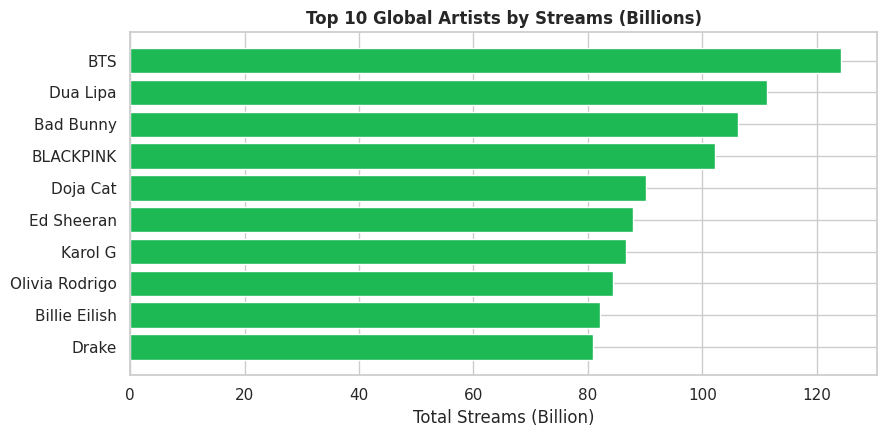

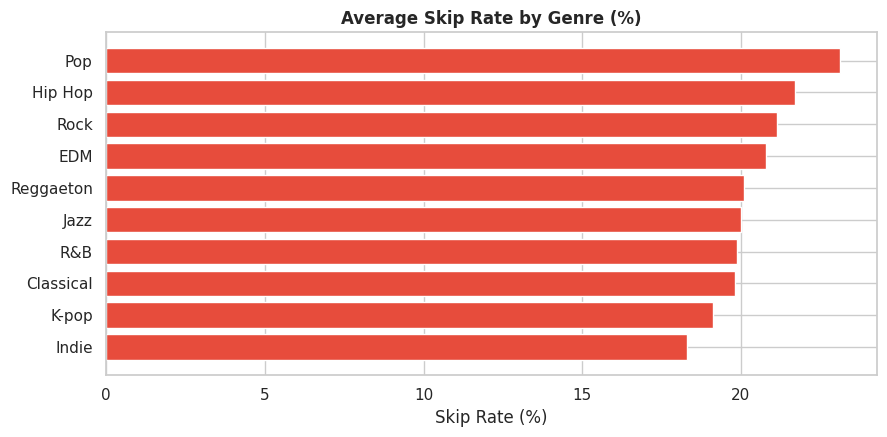

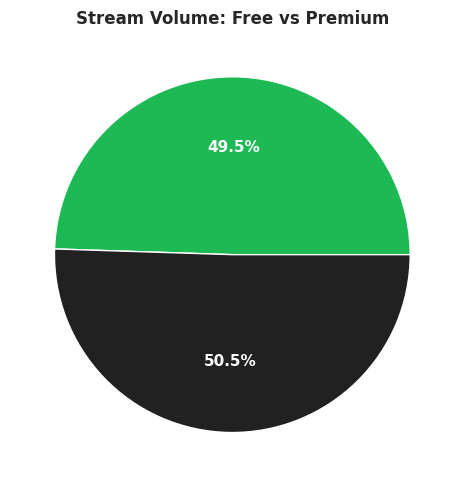

In [5]:
os.makedirs("charts", exist_ok=True)

# 1. Top 10 Artists Bar Chart
plt.figure(figsize=(9, 4.5))
top10 = (
    df.groupby("Artist")["Total Streams (Millions)"]
    .sum()
    .nlargest(10)
    .sort_values()
)
plt.barh(top10.index, top10.values / 1000, color="#1DB954")
plt.title("Top 10 Global Artists by Streams (Billions)", fontweight="bold")
plt.xlabel("Total Streams (Billion)")
plt.tight_layout()
plt.savefig("charts/top_10_artists.png", dpi=300)
plt.show()

# 2. Skip Rate by Genre
plt.figure(figsize=(9, 4.5))
skip_rate = df.groupby("Genre")["Skip Rate (%)"].mean().sort_values()
plt.barh(skip_rate.index, skip_rate.values, color="#e74c3c")
plt.title("Average Skip Rate by Genre (%)", fontweight="bold")
plt.xlabel("Skip Rate (%)")
plt.tight_layout()
plt.savefig("charts/skip_rate_genre.png", dpi=300)
plt.show()

# 3. Platform Distribution (Free vs Premium)
plt.figure(figsize=(5, 5))
platform = df.groupby("Platform Type")["Total Streams (Millions)"].sum()
plt.pie(
    platform,
    labels=platform.index,
    autopct="%1.1f%%",
    colors=["#1DB954", "#212121"],
    textprops={"color": "white", "weight": "bold"},
)
plt.title("Stream Volume: Free vs Premium", fontweight="bold")
plt.tight_layout()
plt.savefig("charts/free_vs_premium.png", dpi=300)
plt.show()


In [6]:
from google.colab import files

# Download clean CSV
files.download("Spotify_2024_Cleaned.csv")

# Zip and download saved charts
!zip -r spotify_charts.zip charts/
files.download("spotify_charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  adding: charts/ (stored 0%)
  adding: charts/skip_rate_genre.png (deflated 28%)
  adding: charts/top_10_artists.png (deflated 27%)
  adding: charts/free_vs_premium.png (deflated 20%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>